# 01 · Market EDA

Synthetic US type 2 diabetes market: our brand **Glyvance** (GLP-1 RA) vs Sitaglin (DPP-4i), Dapaflo (SGLT2i) and the 2024 entrant Glucora (GLP-1 RA).

In [1]:
import os
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# works whether the notebook is run from the repo root or from notebooks/
root = Path.cwd() if (Path.cwd() / "pharmapulse").exists() else Path.cwd().parent
os.environ["PHARMAPULSE_DB"] = str(root / "data" / "pharmapulse.duckdb")
pd.set_option("display.width", 140)
COLORS = {"Glyvance": "#2a78d6", "Sitaglin": "#eb6834", "Dapaflo": "#1baf7a", "Glucora": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "figure.figsize": (10, 4)})

In [2]:
from pharmapulse.db import query
query('SELECT * FROM brands')

,brand,molecule_class,manufacturer,is_our_brand,list_price_per_30d
0,Glyvance,GLP-1 RA,Our Co,True,935.0
1,Sitaglin,DPP-4i,Competitor A,False,540.0
2,Dapaflo,SGLT2i,Competitor B,False,610.0
3,Glucora,GLP-1 RA,Competitor C,False,990.0


## Share of market over time

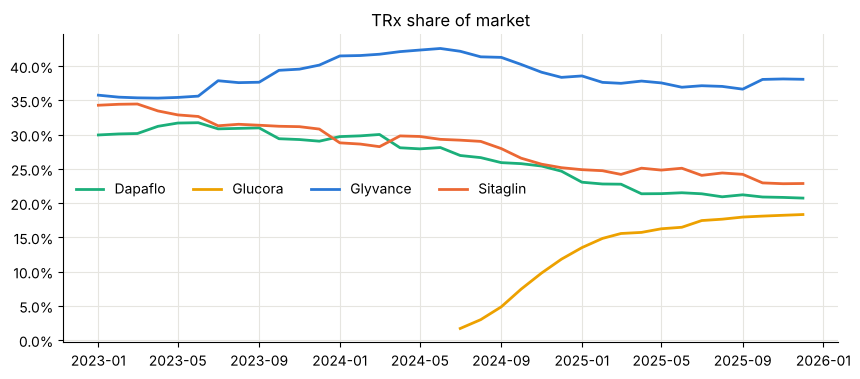

In [3]:
from pharmapulse.analytics import market_share as ms
t = ms.share_trend('trx', 'month')
fig, ax = plt.subplots()
for b, g in t.groupby('brand'):
    ax.plot(g['period'], g['share'], label=b, color=COLORS[b], lw=2)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title('TRx share of market'); ax.legend(frameon=False, ncol=4); plt.show()

In [4]:
ms.growth()

,brand,current,prior_period,same_period_last_year,pop_growth,yoy_growth,current_share
0,Glyvance,96464.0,87825.0,94180.0,0.0984,0.0243,0.3802
1,Sitaglin,58260.0,57648.0,62094.0,0.0106,-0.0617,0.2296
2,Dapaflo,52800.0,50482.0,60488.0,0.0459,-0.1271,0.2081
3,Glucora,46182.0,41844.0,22367.0,0.1037,1.0647,0.1820


## Where do we win? Share by specialty and region (latest 13 weeks)

In [5]:
s = ms.share('trx', 'specialty', start='2025-09-29')
s.pivot(index='specialty', columns='brand', values='share').round(3)

brand,Dapaflo,Glucora,Glyvance,Sitaglin
specialty,,,,
Endocrinology,0.180,0.227,0.480,0.113
Internal Medicine,0.227,0.183,0.357,0.233
Nurse Practitioner,0.201,0.146,0.313,0.340
Primary Care,0.216,0.155,0.336,0.293


In [6]:
s = ms.share('trx', 'region', start='2025-09-29')
s.pivot(index='region', columns='brand', values='share').round(3)

brand,Dapaflo,Glucora,Glyvance,Sitaglin
region,,,,
Midwest,0.180,0.221,0.356,0.243
Northeast,0.153,0.188,0.391,0.268
Southeast,0.278,0.186,0.387,0.149
Southwest,0.202,0.179,0.377,0.242
West,0.211,0.140,0.383,0.266


Glyvance over-indexes in Endocrinology (~48% share vs ~38% overall). Sitaglin (DPP-4i) is strongest with Nurse Practitioners, where it out-writes Glyvance, and weakest in the Southeast, where Glyvance holds a preferred formulary position.

## Patients: persistence and adherence

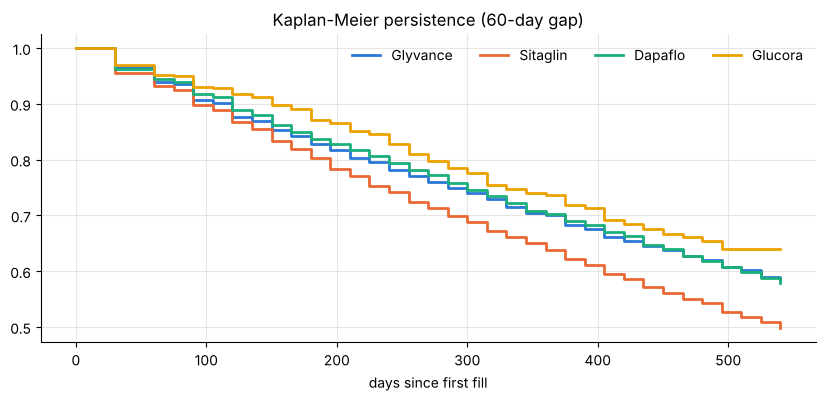

,brand,patients,persistent_90d,persistent_180d,persistent_365d,median_days
1,Glucora,898,0.9307,0.8703,0.7248,NaN
0,Dapaflo,3580,0.9177,0.8371,0.6975,690.0
2,Glyvance,3650,0.9061,0.8276,0.6926,698.0
3,Sitaglin,3872,0.8984,0.8029,0.6308,539.0


In [7]:
from pharmapulse.analytics import patient_journey as pj
fig, ax = plt.subplots()
for b in COLORS:
    k = pj.km_curve(b)
    ax.step(k['day'], k['persistent'], where='post', label=b, color=COLORS[b], lw=2)
ax.set_xlabel('days since first fill'); ax.set_title('Kaplan-Meier persistence (60-day gap)')
ax.legend(frameon=False, ncol=4); plt.show()
pj.persistence()

In [8]:
pj.adherence()

,brand,patients,mean_pdc,pct_adherent
1,Glucora,311,0.8433,0.7685
2,Glyvance,2619,0.8153,0.7354
0,Dapaflo,2584,0.8144,0.7426
3,Sitaglin,2902,0.7679,0.6768


In [9]:
pj.switching_matrix()

,from_brand,to_brand,patients,pct_of_index_patients
3,Glyvance,Dapaflo,259,0.0710
7,Sitaglin,Glyvance,252,0.0651
1,Dapaflo,Glyvance,235,0.0656
5,Sitaglin,Dapaflo,217,0.0560
0,Dapaflo,Glucora,179,0.0500
4,Glyvance,Glucora,162,0.0444
6,Sitaglin,Glucora,130,0.0336
2,Glucora,Glyvance,84,0.0935
